In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.preprocessing import combine_the_data, dict_the_data 

<h3>Importing The Data

In [3]:
#Specific to these scans
path = "scans/data"
scans = []
for x in [19,21,40,42,43]: scans.append(f"00{x}_0_0")
for x in [20,41]: scans.append(f"00{x}_mesh") #41 is wrong circle until point 19
for x in [22,24,26,28,30,32,34,36,38]: scans.append(f"00{x}_centre") #34 is wrong circle
for x in [23,25,27,29,31,33,35,37,39]: scans.append(f"00{x}_dmesh") #Scan 29 is wrong circle 
# for x in range(19,39): scans.append(f"000{x}_*")
print(scans)
scans.sort() #need to sort the scans into the order they were taken!!
print(scans)
x_conversion = 0.1/11
y_conversion = x_conversion

start_cx = 294 #px
start_cy = 260 #px

['0019_0_0', '0021_0_0', '0040_0_0', '0042_0_0', '0043_0_0', '0020_mesh', '0041_mesh', '0022_centre', '0024_centre', '0026_centre', '0028_centre', '0030_centre', '0032_centre', '0034_centre', '0036_centre', '0038_centre', '0023_dmesh', '0025_dmesh', '0027_dmesh', '0029_dmesh', '0031_dmesh', '0033_dmesh', '0035_dmesh', '0037_dmesh', '0039_dmesh']
['0019_0_0', '0020_mesh', '0021_0_0', '0022_centre', '0023_dmesh', '0024_centre', '0025_dmesh', '0026_centre', '0027_dmesh', '0028_centre', '0029_dmesh', '0030_centre', '0031_dmesh', '0032_centre', '0033_dmesh', '0034_centre', '0035_dmesh', '0036_centre', '0037_dmesh', '0038_centre', '0039_dmesh', '0040_0_0', '0041_mesh', '0042_0_0', '0043_0_0']


In [4]:
print(scans)
all_data = dict_the_data(scans, path, x_conversion, y_conversion, start_cx, start_cy)

data_amount = []
data_running_total = 0
for scan in scans: 
    data_amount.append((len(all_data[scan]), len(all_data[scan].dropna())))
    data_running_total = data_running_total + len(all_data[scan].dropna())
    print(scan, " ", data_running_total)
print(data_amount)

['0019_0_0', '0020_mesh', '0021_0_0', '0022_centre', '0023_dmesh', '0024_centre', '0025_dmesh', '0026_centre', '0027_dmesh', '0028_centre', '0029_dmesh', '0030_centre', '0031_dmesh', '0032_centre', '0033_dmesh', '0034_centre', '0035_dmesh', '0036_centre', '0037_dmesh', '0038_centre', '0039_dmesh', '0040_0_0', '0041_mesh', '0042_0_0', '0043_0_0']
0019_0_0   2
0020_mesh   597
0021_0_0   599
0022_centre   601
0023_dmesh   888
0024_centre   890
0025_dmesh   1175
0026_centre   1177
0027_dmesh   1462
0028_centre   1464
0029_dmesh   1753
0030_centre   1755
0031_dmesh   2029
0032_centre   2031
0033_dmesh   2310
0034_centre   2312
0035_dmesh   2582
0036_centre   2584
0037_dmesh   2858
0038_centre   2860
0039_dmesh   3143
0040_0_0   3145
0041_mesh   3560
0042_0_0   3561
0043_0_0   3562
[(2, 2), (625, 595), (2, 2), (2, 2), (289, 287), (2, 2), (289, 285), (2, 2), (289, 285), (2, 2), (289, 289), (2, 2), (289, 274), (2, 2), (289, 279), (2, 2), (289, 270), (2, 2), (289, 274), (2, 2), (289, 283), (2, 

<h3>Correcting The Data - wrong circle detected

In [5]:
#Correct for wrong circles
for scan in ["0029_dmesh", "0034_centre", "0028_centre"]:
    all_data[scan]["cx"] = all_data[scan]["cx"] - 368
    all_data[scan]["cx_rel"] = all_data[scan]["cx"] - 294
    all_data[scan]["cx_mm"] = -all_data[scan]["cx_rel"]*x_conversion


In [6]:
#41 is wrong circle until point 19
display(all_data["0041_mesh"]["cx"].head())
for i in range(18):
    all_data["0041_mesh"].loc[i, "cx"] = all_data["0041_mesh"].loc[i, "cx"]- 368
    all_data["0041_mesh"].loc[i,"cx_rel"] = all_data["0041_mesh"].loc[i,"cx"] - start_cx
    all_data["0041_mesh"].loc[i,"cx_mm"] = -all_data["0041_mesh"].loc[i,"cx_rel"]*x_conversion
display(all_data["0041_mesh"]["cx"].head())

0    516.0
1    528.0
2    550.0
3      NaN
4      NaN
Name: cx, dtype: float64

0    148.0
1    160.0
2    182.0
3      NaN
4      NaN
Name: cx, dtype: float64

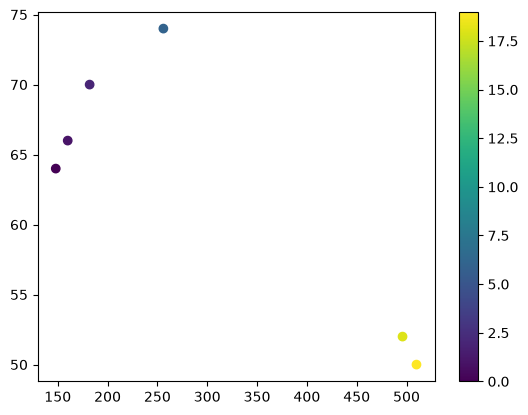

In [7]:
plt.scatter(all_data["0041_mesh"]["cx"].head(20), all_data["0041_mesh"]["cy"].head(20), c=all_data["0041_mesh"]["point"].head(20))
plt.colorbar()

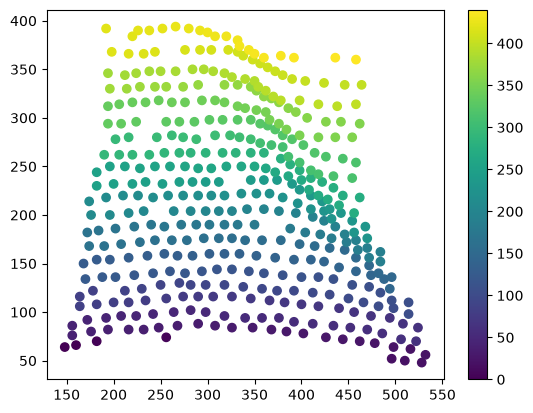

In [8]:
plt.scatter(all_data["0041_mesh"]["cx"], all_data["0041_mesh"]["cy"], c=all_data["0041_mesh"]["point"])
plt.colorbar()

<h2> Saving the data

3694
3562
      point      time    x    y      x_rb  y_rb    s0    s1    s2  strain  \
0         0    1.2720  0.0  0.0  0.000000   0.0     0     0     0     0.0   
1         1    2.6999  0.0  0.0  0.000000   0.0     0     0     0     0.0   
2         0   23.0354  1.2  1.2  1.200032   1.2  6144 -8393  2249     0.0   
3         1   25.1267  1.1  1.2  1.099897   1.2  6144 -7949  1805     0.0   
4         2   27.2019  1.0  1.2  0.999989   1.2  6144 -7506  1362     0.0   
...     ...       ...  ...  ...       ...   ...   ...   ...   ...     ...   
3690    440  934.4870 -1.0 -1.0 -0.999989  -1.0 -5120  6994 -1874     0.0   
3691      0   20.0180  0.0  0.0  0.000000   0.0     0     0     0     0.0   
3692      1   21.5576  0.0  0.0  0.000000   0.0     0     0     0     0.0   
3693      0    1.2807  0.0  0.0  0.000000   0.0     0     0     0     0.0   
3694      1    2.7727  0.0  0.0  0.000000   0.0     0     0     0     0.0   

      ...  track_cy  track_radius  roi_x_min  roi_y_min  roi_x_ma

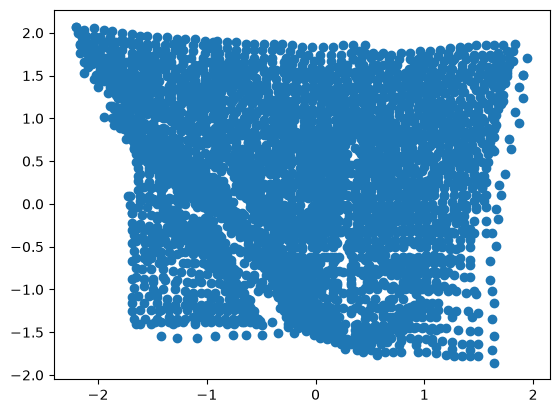

In [44]:

data_concat = pd.concat(all_data,ignore_index=True)
plt.scatter(data_concat["cx_mm"], data_concat["cy_mm"])
print(data_concat.last_valid_index())
print(len(data_concat.dropna()))
print(data_concat)

In [45]:
data_concat.dtypes

point             int64
time            float64
x               float64
y               float64
x_rb            float64
y_rb            float64
s0                int64
s1                int64
s2                int64
strain          float64
frame_id          int64
n_circles         int64
cx              float64
cy              float64
radius          float64
detected          int64
track_cx        float64
track_cy        float64
track_radius    float64
roi_x_min       float64
roi_y_min       float64
roi_x_max       float64
roi_y_max       float64
cx_rel          float64
cy_rel          float64
cx_mm           float64
cy_mm           float64
dtype: object

In [46]:
data_concat.astype("float32").dtypes

point           float32
time            float32
x               float32
y               float32
x_rb            float32
y_rb            float32
s0              float32
s1              float32
s2              float32
strain          float32
frame_id        float32
n_circles       float32
cx              float32
cy              float32
radius          float32
detected        float32
track_cx        float32
track_cy        float32
track_radius    float32
roi_x_min       float32
roi_y_min       float32
roi_x_max       float32
roi_y_max       float32
cx_rel          float32
cy_rel          float32
cx_mm           float32
cy_mm           float32
dtype: object

In [47]:
data_concat = data_concat.astype("float32")
data_concat.to_csv("processed_data/16Oct_data_corrected.csv")

<h3>Plotting The Data

Text(0.5, 1.0, 'set x and y values. 16th Oct')

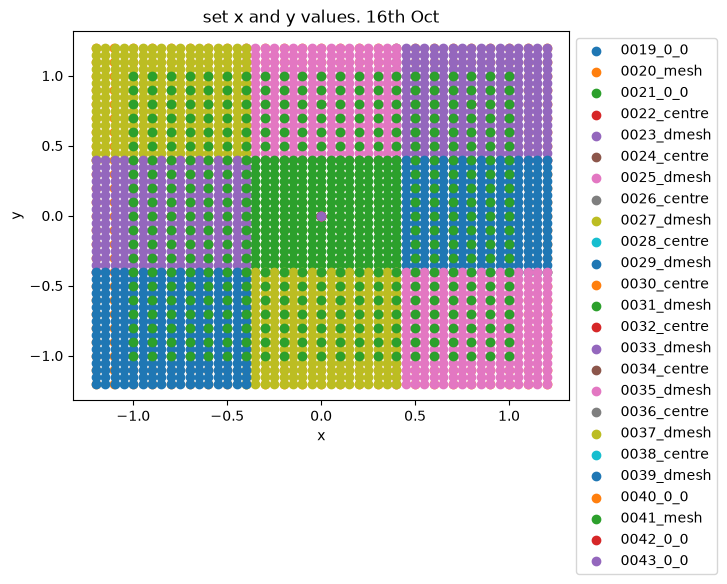

In [48]:
cmap=plt.get_cmap('Paired')
for i, scan in enumerate(scans): 
    plt.scatter(all_data[scan]["x"], all_data[scan]["y"], label=scan) # , color=cmap(i))
plt.ylabel("y")
plt.xlabel("x")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("set x and y values. 16th Oct")

Text(0.5, 1.0, 'measured cx and cy values 16th Oct')

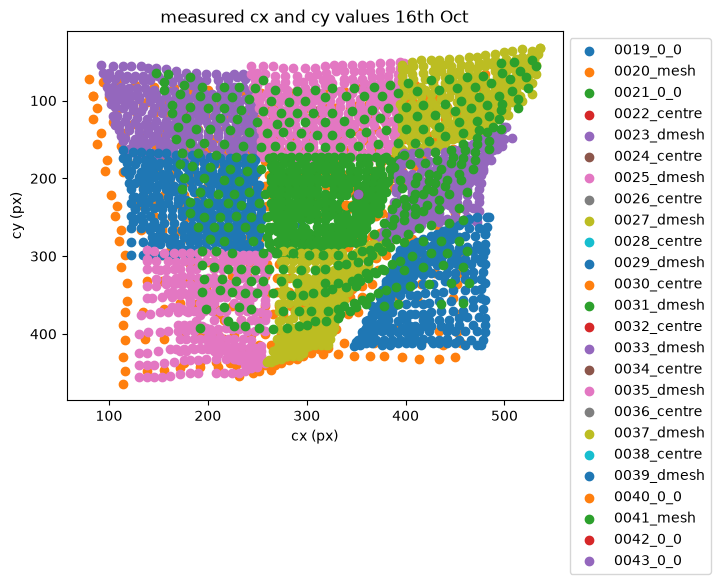

In [49]:
for i, scan in enumerate(scans): 
    plt.scatter(all_data[scan]["cx"], all_data[scan]["cy"], label=scan) #, color=cmap(i))
plt.ylabel("cy (px)")
plt.xlabel("cx (px)")
plt.gca().invert_yaxis()
# plt.scatter(382, -270, label="initial (0,0)")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("measured cx and cy values 16th Oct")

Text(0.5, 1.0, 'converted cx and cy values 16th Oct')

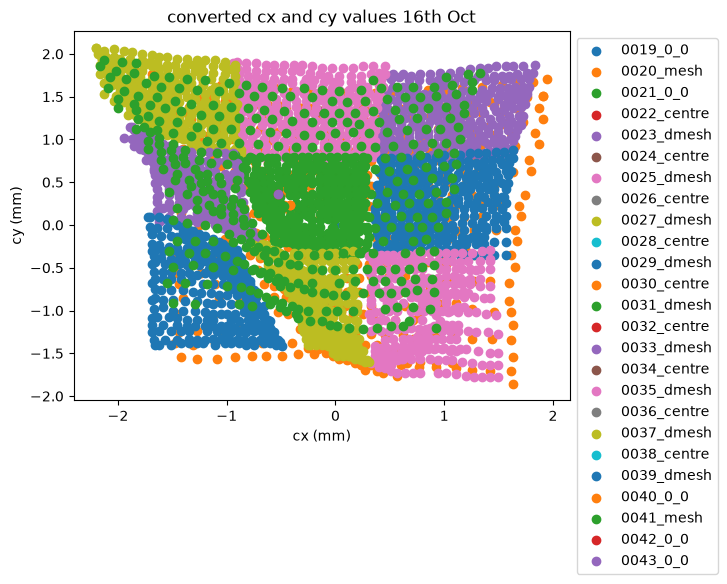

In [50]:
for i, scan in enumerate(scans): 
    plt.scatter(all_data[scan]["cx_mm"], all_data[scan]["cy_mm"], label=scan) #, color=cmap(i))
plt.ylabel("cy (mm)")
plt.xlabel("cx (mm)")
# plt.gca().invert_yaxis()
# plt.scatter(382*x_conversion, -270*y_conversion, label="initial (0,0)")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("converted cx and cy values 16th Oct")

In [51]:
#check didn't track the wrong circle at one point by looking at the radius 
for scan in scans: 
    print(scan, "max: ", max(all_data[scan]["radius"].dropna()), "min: ", min(all_data[scan]["radius"].dropna()))
#all 5 or 6 - good 

0019_0_0 max:  6 min:  6
0020_mesh max:  6.0 min:  6.0
0021_0_0 max:  6 min:  6
0022_centre max:  6 min:  6
0023_dmesh max:  6.0 min:  6.0
0024_centre max:  6 min:  6
0025_dmesh max:  6.0 min:  6.0
0026_centre max:  6 min:  6
0027_dmesh max:  6.0 min:  6.0
0028_centre max:  6 min:  6
0029_dmesh max:  6 min:  6
0030_centre max:  6 min:  6
0031_dmesh max:  6.0 min:  6.0
0032_centre max:  6 min:  6
0033_dmesh max:  6.0 min:  6.0
0034_centre max:  6 min:  6
0035_dmesh max:  6.0 min:  6.0
0036_centre max:  6 min:  6
0037_dmesh max:  6.0 min:  6.0
0038_centre max:  6 min:  6
0039_dmesh max:  6.0 min:  6.0
0040_0_0 max:  6 min:  6
0041_mesh max:  6.0 min:  5.0
0042_0_0 max:  6.0 min:  6.0
0043_0_0 max:  6.0 min:  6.0


Text(0, 0, 'Colour = point')

<Figure size 640x480 with 0 Axes>

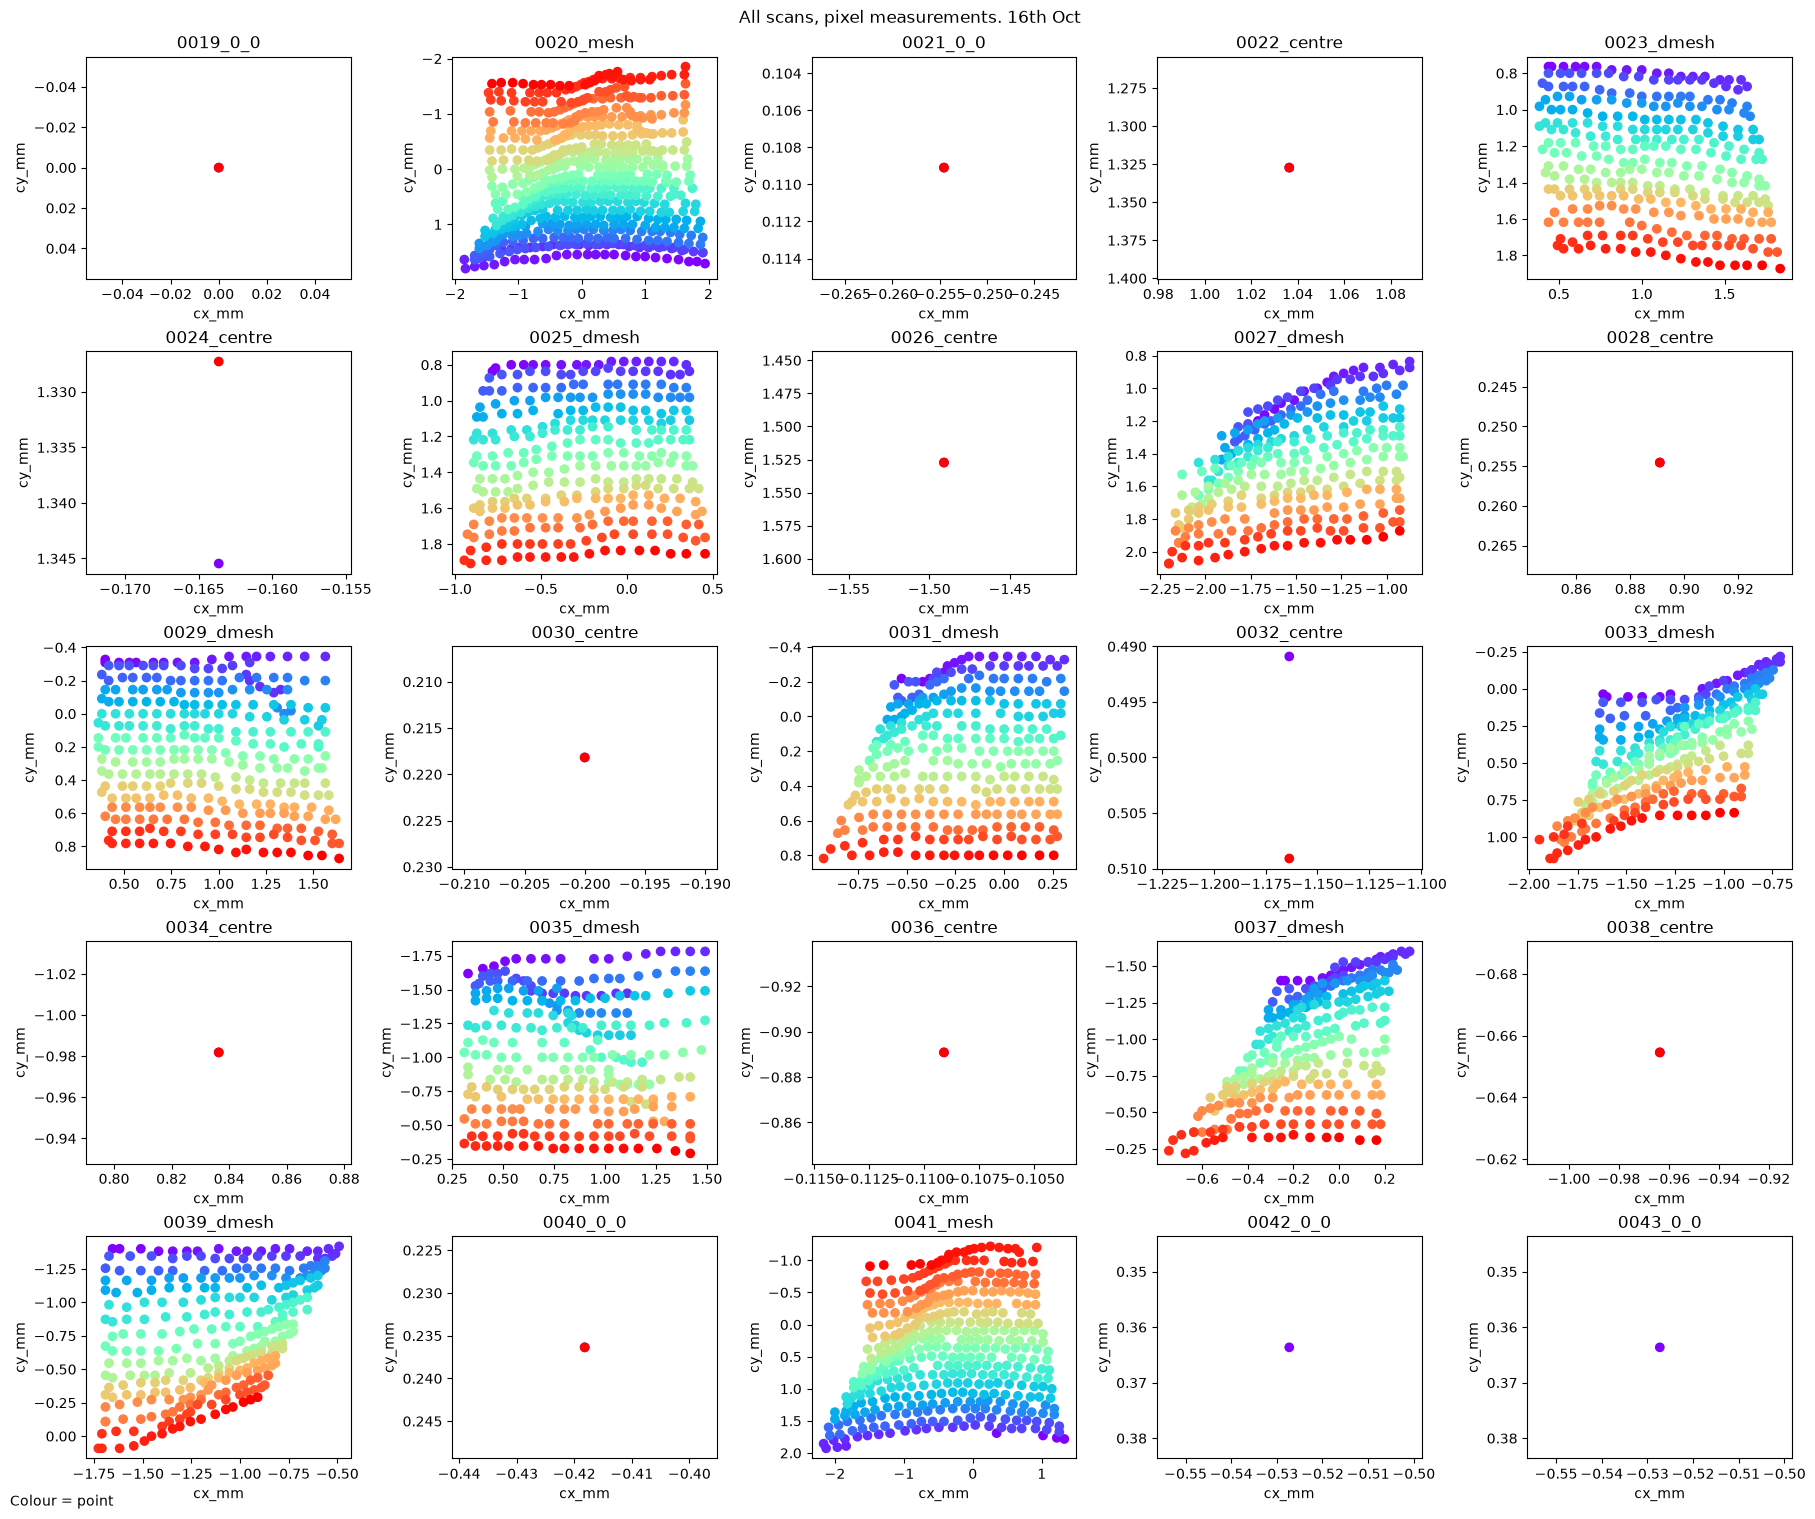

In [52]:
fig = plt.figure()
fig, ax = plt.subplots(5, 5, figsize=(18,15), constrained_layout=True)    

key = 0

for i in range(5):
    for j in range(5):
        subplot = ax[i,j]
        # print(key)
        dfAtKey = scans[key]
        # print(dfAtKey)
        ax[i,j].scatter(all_data[dfAtKey]["cx_mm"], all_data[dfAtKey]["cy_mm"], label=scan, c=all_data[dfAtKey]["point"], cmap="rainbow")
        ax[i,j].yaxis.set_inverted(True)
        subplot.set_title(scans[key])
        ax[i,j].set_xlabel("cx_mm")
        ax[i,j].set_ylabel("cy_mm")
        # for ind in dfAtKey.index:
        #     subplot.scatter(dfAtKey.loc[ind,0] , dfAtKey.loc[ind,1] , width = 0.5,  label=scan)

        key += 1

fig.suptitle("All scans, pixel measurements. 16th Oct")
fig.text(0,0,"Colour = point")

In [53]:
print(scans)

['0019_0_0', '0020_mesh', '0021_0_0', '0022_centre', '0023_dmesh', '0024_centre', '0025_dmesh', '0026_centre', '0027_dmesh', '0028_centre', '0029_dmesh', '0030_centre', '0031_dmesh', '0032_centre', '0033_dmesh', '0034_centre', '0035_dmesh', '0036_centre', '0037_dmesh', '0038_centre', '0039_dmesh', '0040_0_0', '0041_mesh', '0042_0_0', '0043_0_0']


Text(0, 0, 'Colour = y \n scans 28, 29 and 34 tracked the wrong circle')

<Figure size 640x480 with 0 Axes>

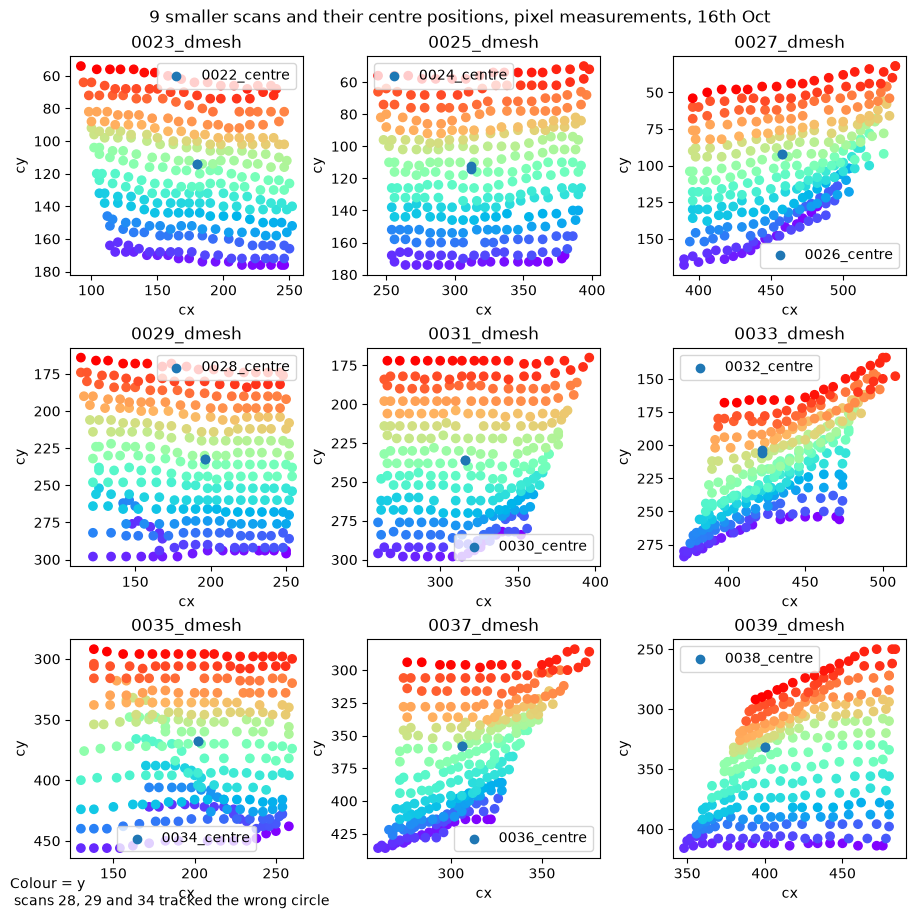

In [54]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(9,9), constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]
        # print(key)
        dfAtKey = scans_to_plot[key]
        dfCentre = scans[scans_i[key]-1]
        # print(dfAtKey)
        ax[i,j].scatter(all_data[dfAtKey]["cx"], all_data[dfAtKey]["cy"], c=all_data[dfAtKey]["point"], cmap="rainbow") #label=scans_to_plot[key], 
        ax[i,j].scatter(all_data[dfCentre]["cx"], all_data[dfCentre]["cy"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        ax[i,j].yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        ax[i,j].set_xlabel("cx")
        ax[i,j].set_ylabel("cy")
        ax[i,j].legend()
        # for ind in dfAtKey.index:
        #     subplot.scatter(dfAtKey.loc[ind,0] , dfAtKey.loc[ind,1] , width = 0.5,  label=scan)

        key += 1
fig.suptitle("9 smaller scans and their centre positions, pixel measurements, 16th Oct")
fig.text(0,0,"Colour = y \n scans 28, 29 and 34 tracked the wrong circle")

(294.0, 294.0)
(322.0, 322.0)
(340.0, 340.0)
(nan, nan)
[np.int64(294), np.int64(322), np.int64(340), np.float64(352.0)]
[np.int64(260), np.int64(248), np.int64(234), np.float64(220.0)]
           2
-0.009027 x + 5.148 x - 473.2


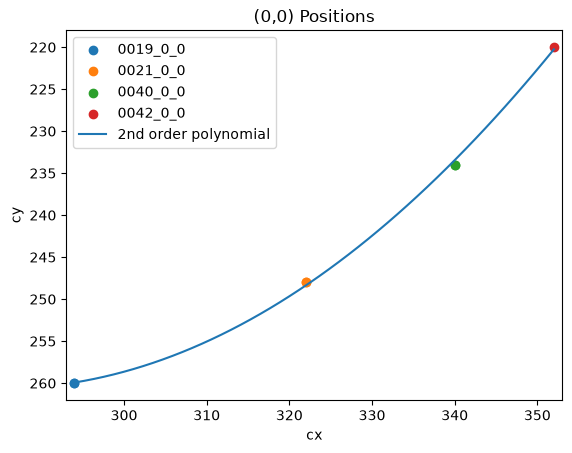

In [55]:
import math
fig, ax = plt.subplots()    

scans_i = [0,2,21,23]#,24]
scans_to_plot = [scans[i] for i in scans_i]
cx_0_0 = []
cy_0_0 = []

for scan in scans_to_plot:
    ax.scatter(all_data[scan]["cx"], all_data[scan]["cy"], label=scan) #, c=all_data[scan], cmap="rainbow")
    print((float(all_data[scan]["cx"][0]), float((all_data[scan]["cx"][0]))))
    ax.annotate(scan, (float(all_data[scan]["cx"][0]), float((all_data[scan]["cx"][0]))))
    if math.isnan(all_data[scan]["cx"][0]):
        cx_0_0.append(all_data[scan]["cx"][1])
    else: cx_0_0.append(all_data[scan]["cx"][0])
    if math.isnan(all_data[scan]["cy"][0]):
        cy_0_0.append(all_data[scan]["cy"][1])
    else: cy_0_0.append(all_data[scan]["cy"][0])

ax.yaxis.set_inverted(True)
ax.legend()
ax.set_ylabel("cy")
ax.set_xlabel("cx")
ax.set_title("(0,0) Positions")

print(cx_0_0)
print(cy_0_0)
z = np.polyfit(cx_0_0, cy_0_0, 2)
f = np.poly1d(z)
print(f)
# calculate new x's and y's
x_new = np.linspace(cx_0_0[0], cx_0_0[-1], 50)
y_new = f(x_new)
plt.plot(x_new, y_new, label="2nd order polynomial")
plt.xlim([cx_0_0[0]-1, cx_0_0[-1] + 1 ])
plt.legend()


Text(0, -0.02, 'Colour = y\nScans 28, 29 and 34 tracked the wrong circle')

<Figure size 640x480 with 0 Axes>

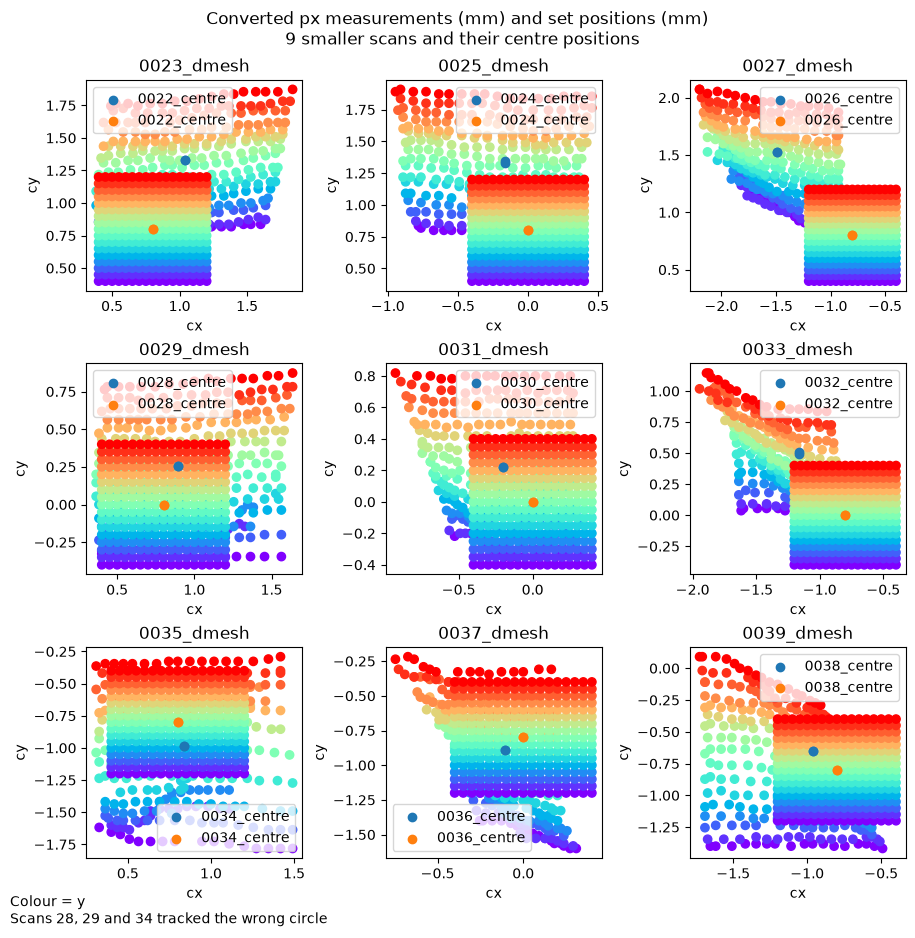

In [56]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(9,9), constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]

        dfAtKey = scans_to_plot[key]
        

        subplot.scatter(all_data[dfAtKey]["cx_mm"], all_data[dfAtKey]["cy_mm"], c=all_data[dfAtKey]["y"], cmap="rainbow") #label=scans_to_plot[key], 
        subplot.scatter(all_data[dfAtKey]["x"], all_data[dfAtKey]["y"], c=all_data[dfAtKey]["y"], cmap="rainbow") #label=scans_to_plot[key], 

        #plot centre points
        dfCentre = scans[scans_i[key]-1]
        subplot.scatter(all_data[dfCentre]["cx_mm"], all_data[dfCentre]["cy_mm"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        subplot.scatter(all_data[dfCentre]["x"], all_data[dfCentre]["y"], label=scans[scans_i[key]-1])

        # subplot.yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        subplot.set_xlabel("cx")
        subplot.set_ylabel("cy")
        subplot.legend()

        key += 1
fig.suptitle("Converted px measurements (mm) and set positions (mm) \n 9 smaller scans and their centre positions")
fig.text(0,-0.02,"Colour = y\nScans 28, 29 and 34 tracked the wrong circle")

0023_dmesh 0     -0.363636
1     -0.363636
2     -0.363636
3     -0.363636
4     -0.363636
         ...   
284   -0.654545
285   -0.654545
286   -0.654545
287   -0.654545
288   -0.672727
Length: 289, dtype: float64
0025_dmesh 0     -0.436364
1     -0.418182
2     -0.400000
3     -0.400000
4     -0.400000
         ...   
284   -0.636364
285   -0.636364
286   -0.654545
287   -0.654545
288   -0.654545
Length: 289, dtype: float64
0027_dmesh 0           NaN
1     -0.836364
2     -0.800000
3     -0.763636
4     -0.727273
         ...   
284   -0.727273
285   -0.727273
286   -0.727273
287   -0.709091
288   -0.672727
Length: 289, dtype: float64
0029_dmesh 0     -0.090909
1     -0.072727
2     -0.090909
3     -0.090909
4     -0.090909
         ...   
284   -0.436364
285   -0.436364
286   -0.454545
287   -0.454545
288   -0.472727
Length: 289, dtype: float64
0031_dmesh 0     -0.181818
1           NaN
2     -0.200000
3     -0.181818
4     -0.163636
         ...   
284   -0.400000
285   -0.400000
2

Text(0, -0.02, "Colour = difference between measured point and set point\n not sure what's going on with 27")

<Figure size 640x480 with 0 Axes>

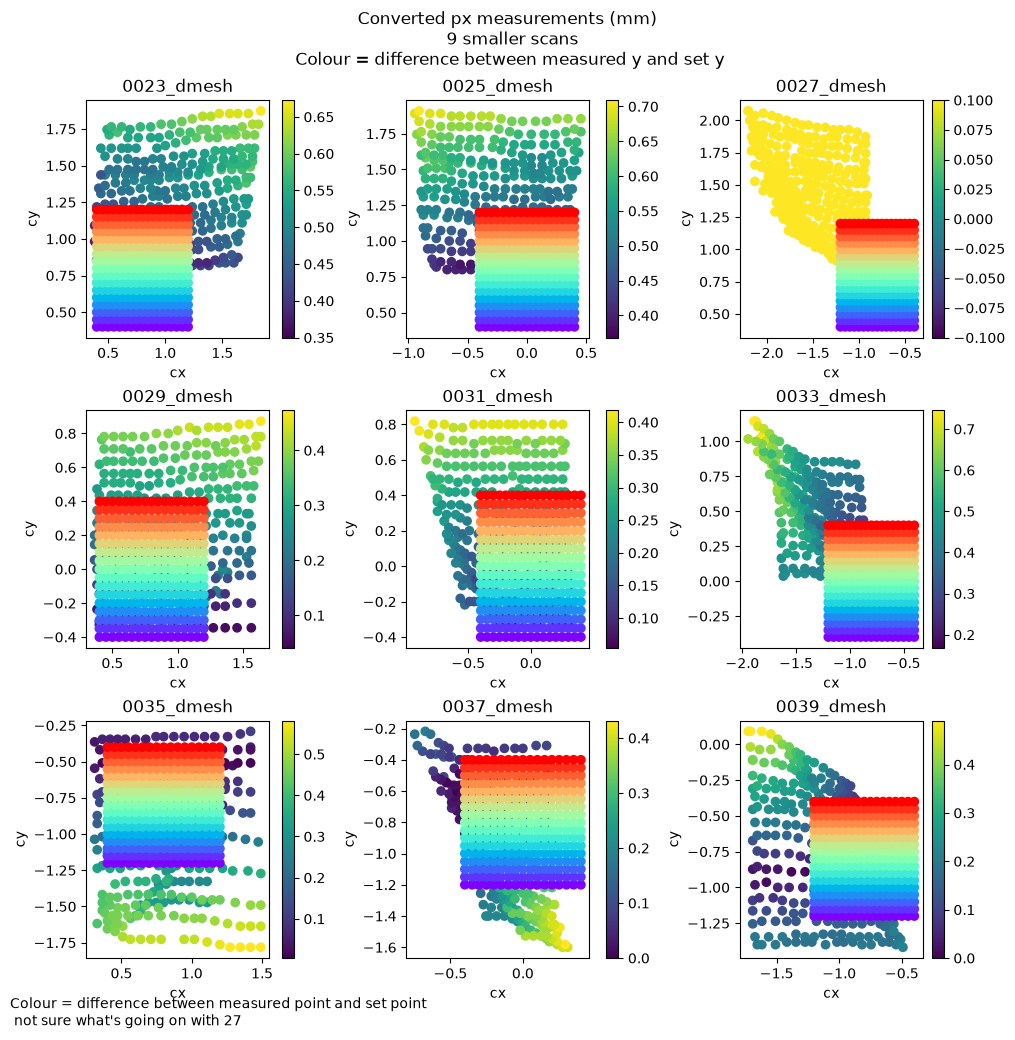

In [57]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(10,10),  constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]

        dfAtKey = scans_to_plot[key]

        difference = all_data[dfAtKey]["y"] - all_data[dfAtKey]["cy_mm"]
        print(dfAtKey, difference)

        im = subplot.scatter(all_data[dfAtKey]["cx_mm"], all_data[dfAtKey]["cy_mm"], c=abs(difference), vmin=min(abs(difference)), vmax=max(abs(difference))) #cmap="rainbow") #label=scans_to_plot[key], 
        subplot.scatter(all_data[dfAtKey]["x"], all_data[dfAtKey]["y"], c=all_data[dfAtKey]["y"], cmap="rainbow") #label=scans_to_plot[key], 
        

        #plot centre points
        # dfCentre = scans[scans_i[key]-1]
        # subplot.scatter(all_data[dfCentre]["cx_mm"], all_data[dfCentre]["cy_mm"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        # subplot.scatter(all_data[dfCentre]["x"], all_data[dfCentre]["y"], label=scans[scans_i[key]-1])

        # subplot.yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        subplot.set_xlabel("cx")
        subplot.set_ylabel("cy")
        # subplot.legend()
        fig.colorbar(im, ax=subplot)  
        key += 1
# plt.colorbar(im, ax=ax.ravel().tolist())  
# sm =  ScalarMappable(norm=norm, cmap=cmap)
# sm.set_array([])
# cbar = fig.colorbar(sm, ax=axes[:,1])
# cbar.ax.set_title("scale")
fig.suptitle("Converted px measurements (mm) \n 9 smaller scans\nColour = difference between measured y and set y")
fig.text(0,-0.02,"Colour = difference between measured point and set point\n not sure what's going on with 27") #\nScans 28, 29 and 34 tracked the wrong circle

Text(0, -0.02, 'Colour = difference between measured point and set point')

<Figure size 640x480 with 0 Axes>

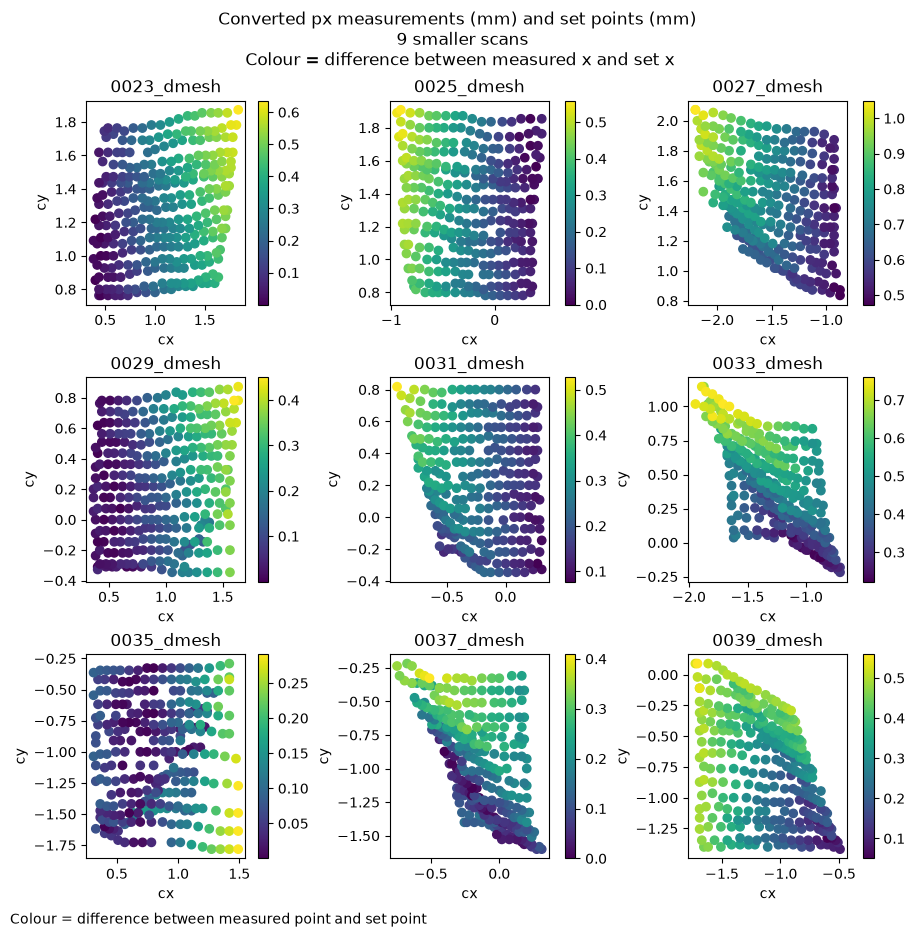

In [58]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(9,9), constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]

        dfAtKey = scans_to_plot[key]

        difference = all_data[dfAtKey]["x"] - all_data[dfAtKey]["cx_mm"]
        # print(difference)

        im = subplot.scatter(all_data[dfAtKey]["cx_mm"], all_data[dfAtKey]["cy_mm"], c=abs(difference)) #cmap="rainbow") #label=scans_to_plot[key], 
        #subplot.scatter(all_data[dfAtKey]["x"], all_data[dfAtKey]["y"], c=all_data[dfAtKey]["y"], cmap="rainbow") #label=scans_to_plot[key], 

        #plot centre points
        # dfCentre = scans[scans_i[key]-1]
        # subplot.scatter(all_data[dfCentre]["cx_mm"], all_data[dfCentre]["cy_mm"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        # # subplot.scatter(all_data[dfCentre]["x"], all_data[dfCentre]["y"], label=scans[scans_i[key]-1])

        # subplot.yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        subplot.set_xlabel("cx")
        subplot.set_ylabel("cy")
        fig.colorbar(im, ax=subplot)  
        # subplot.legend()

        key += 1
# plt.colorbar(im, ax=ax.ravel().tolist())  
fig.suptitle("Converted px measurements (mm) and set points (mm) \n 9 smaller scans\nColour = difference between measured x and set x")
fig.text(0,-0.02,"Colour = difference between measured point and set point") #\nScans 28, 29 and 34 tracked the wrong circle")

Text(0, 0, 'Colour = point')

<Figure size 640x480 with 0 Axes>

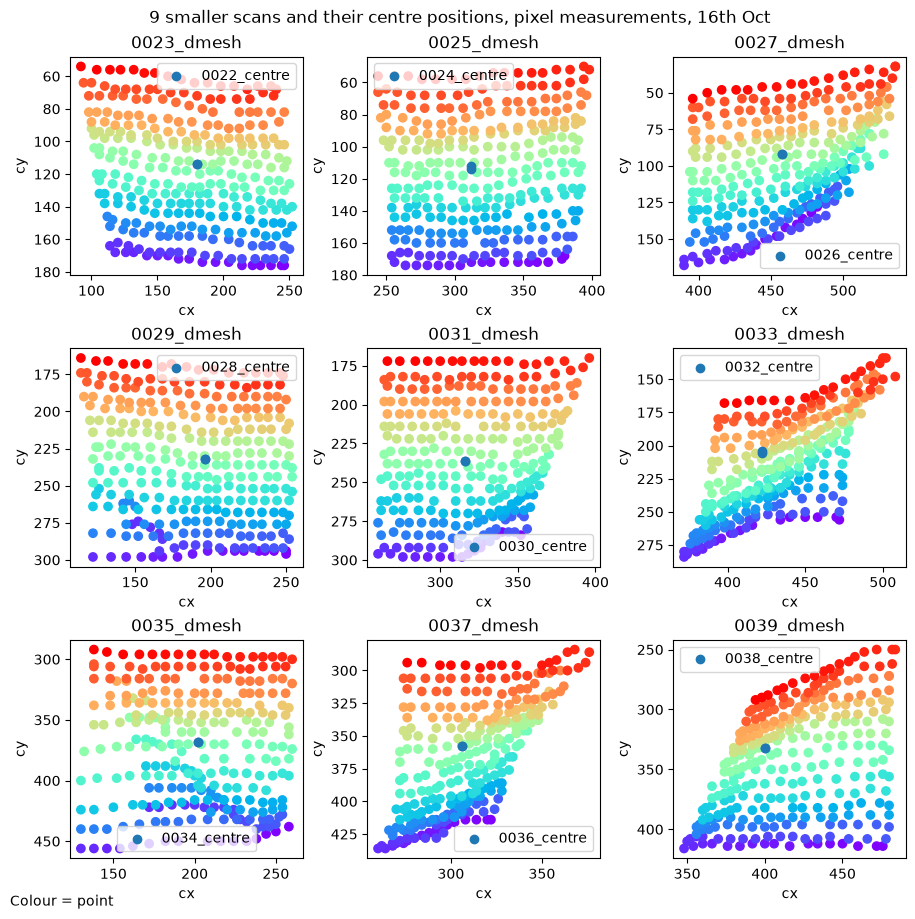

In [59]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(9,9), constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]
        # print(key)
        dfAtKey = scans_to_plot[key]
        dfCentre = scans[scans_i[key]-1]
        # print(dfAtKey)
        ax[i,j].scatter(all_data[dfAtKey]["cx"], all_data[dfAtKey]["cy"], c=all_data[dfAtKey]["point"], cmap="rainbow") #label=scans_to_plot[key], 
        ax[i,j].scatter(all_data[dfCentre]["cx"], all_data[dfCentre]["cy"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        ax[i,j].yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        ax[i,j].set_xlabel("cx")
        ax[i,j].set_ylabel("cy")
        ax[i,j].legend()
        # for ind in dfAtKey.index:
        #     subplot.scatter(dfAtKey.loc[ind,0] , dfAtKey.loc[ind,1] , width = 0.5,  label=scan)

        key += 1
fig.suptitle("9 smaller scans and their centre positions, pixel measurements, 16th Oct")
fig.text(0,0,"Colour = point")# \n scans 28, 29 and 34 tracked the wrong circle")

Text(0.5, 1.0, '16Oct 0020_mesh')

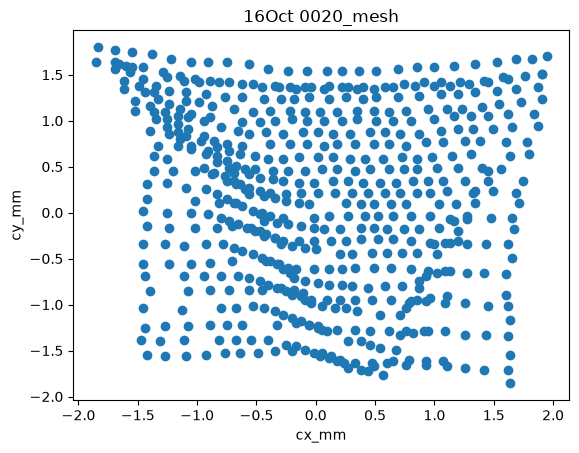

In [14]:
scan = "0020_mesh"
plt.scatter(all_data[scan]["cx_mm"], all_data[scan]["cy_mm"])
# plt.scatter(all_data[scan]["x"], all_data[scan]["y"], c= all_data[scan]["point"])
plt.xlabel("cx_mm")
plt.ylabel("cy_mm")
plt.title(f"16Oct {scan}")